# Experiment 17: RNN Gradient Analysis and Gradient Clipping

A character-level generator becomes unstable at a high learning rate. We train a small recurrent language model on a built-in sample corpus, log global gradient norms and compare unclipped, clipnorm and clipvalue training.

**Tools:** TensorFlow, Keras, NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Train an RNN without clipping and log each global gradient norm.  2. Locate spikes or non-finite loss.  3. Retrain with clipnorm and clipvalue thresholds.  4. Plot gradient norms and loss.  5. Recommend a clipping setting from observed stability.

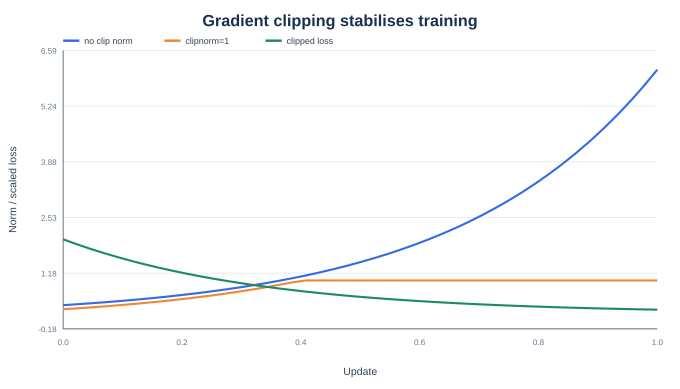

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(17)
text=("deep learning models learn representations from data. "
      "recurrent networks process sequences one step at a time. ")*80
vocab=sorted(set(text)); char_to_id={c:i for i,c in enumerate(vocab)}
encoded=np.array([char_to_id[c] for c in text],dtype=np.int32)
seq_len=32
starts=np.arange(0,len(encoded)-seq_len-1,3)
X=np.array([encoded[i:i+seq_len] for i in starts])
Y=np.array([encoded[i+1:i+seq_len+1] for i in starts])
X=tf.constant(X);Y=tf.constant(Y)
def run_training(mode,threshold,steps=120):
    model=tf.keras.Sequential([tf.keras.layers.Embedding(len(vocab),24),
        tf.keras.layers.SimpleRNN(48,return_sequences=True),
        tf.keras.layers.Dense(len(vocab))])
    opt=tf.keras.optimizers.SGD(learning_rate=.8)
    norms=[];losses=[]
    for step in range(steps):
        idx=np.random.randint(0,len(X),32)
        with tf.GradientTape() as tape:
            logits=model(tf.gather(X,idx),training=True)
            loss=tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(
                tf.gather(Y,idx),logits,from_logits=True))
        grads=tape.gradient(loss,model.trainable_variables)
        norm=tf.linalg.global_norm(grads)
        norms.append(float(norm));losses.append(float(loss))
        if mode=="clipnorm": grads,_=tf.clip_by_global_norm(grads,threshold)
        elif mode=="clipvalue": grads=[tf.clip_by_value(g,-threshold,threshold) for g in grads]
        opt.apply_gradients(zip(grads,model.trainable_variables))
        if not np.isfinite(losses[-1]): break
    return np.array(norms),np.array(losses)
runs={
 "no clipping":run_training("none",0),
 "clipnorm=1.0":run_training("clipnorm",1.0),
 "clipvalue=0.5":run_training("clipvalue",.5)
}
for name,(norms,losses) in runs.items():
    spikes=np.flatnonzero(norms>10)
    print(f"{name}: steps={len(losses)}, max norm={np.nanmax(norms):.2f}, "
          f"non-finite losses={(~np.isfinite(losses)).sum()}, first norm>10={spikes[0] if len(spikes) else 'none'}")
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,(norms,losses) in runs.items():
    axes[0].plot(norms,label=name);axes[1].plot(losses,label=name)
axes[0].set(title="Global gradient norm",xlabel="Update",yscale="log")
axes[1].set(title="Training loss",xlabel="Update")
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print("For this run, clipnorm=1.0 bounds each update's global norm and is the recommended stable starting point; tune it on validation data.")